# From a research question to a numerical model

**Source:** CompSci §§1.1–1.3, pp. 4–6; Introduction slides 2–7, 9–18 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

Ask whether a temperature anomaly relaxes toward equilibrium. A well-mixed deterministic model has state $T$, rate parameter $a>0$, and IVP $T'=-aT$, $T(0)=1$. It ignores spatial gradients and external input. A stochastic model could describe unresolved fluctuations; a statistical model could predict from data; an optimisation model could choose a control. The choice depends on the question, the available data and the cost of a simulation.

A well-posed problem has existence, uniqueness and continuous dependence on its data. Decide which invariants or decay rates the method should reproduce, then check cost and accuracy. Verification compares the computation with the mathematical model, for example an exact solution. Empirical validation compares the model with observations. Model error, parameter uncertainty, discretisation error, roundoff and implementation mistakes have different remedies.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


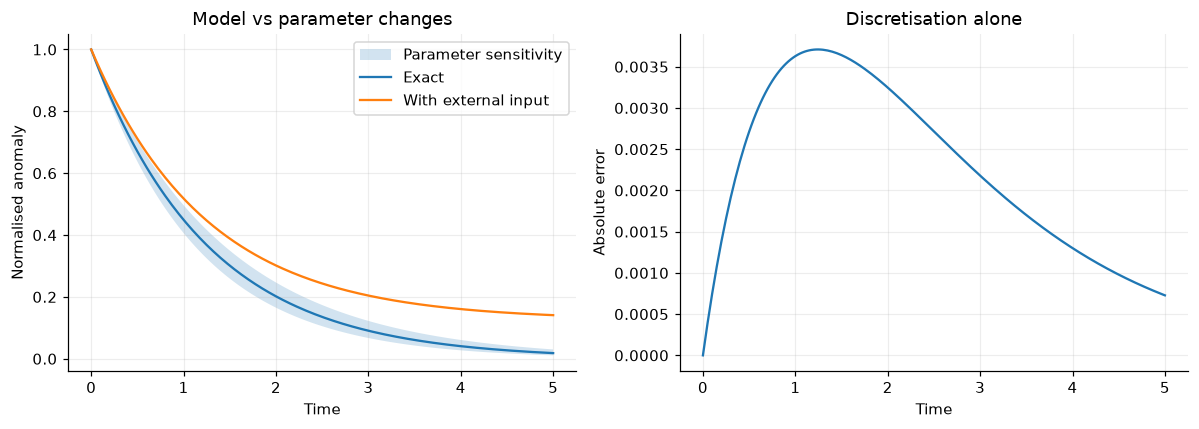

In [2]:
t=np.linspace(0,5,201); a=.8; dt=t[1]-t[0]
exact=np.exp(-a*t); euler=(1-a*dt)**np.arange(t.size)
forced=exact+.1/a*(1-exact)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].fill_between(t,np.exp(-.9*t),np.exp(-.7*t),alpha=.2,label="Parameter sensitivity")
ax[0].plot(t,exact,label="Exact"); ax[0].plot(t,forced,label="With external input")
ax[0].set(xlabel="Time",ylabel="Normalised anomaly",title="Model vs parameter changes"); ax[0].legend()
ax[1].plot(t,abs(euler-exact)); ax[1].set(xlabel="Time",ylabel="Absolute error",title="Discretisation alone")
show(fig,"02-model-errors")
assert np.max(abs(euler-exact))<.004
assert abs(forced[-1]-exact[-1])>20*np.max(abs(euler-exact))

## Worked exercise

**The code matches the exact solution but misses measurements. What passed?** One verification test. Check assumptions and parameter uncertainties before reducing the timestep. The band is a chosen sensitivity range, not a confidence interval.

## Further practice

Explain how a changing ambient temperature changes the equation. Which additional observations would be needed for validation?

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.